# 73 — Human-centered AI audit

This lightweight practice changes the question from **How accurate is the model?** to **Where does it fail, what do errors cost, and when should it abstain?** We train one small CIFAR-10 classifier and audit it from several perspectives rather than introducing another architecture.

The brightness groups and error costs below are deliberately synthetic. CIFAR-10 does not support meaningful conclusions about demographic fairness, healthcare, or real privacy. The goal is to practice evaluation mechanics and careful interpretation.

Companion notes: [Human-centered AI and visual intelligence](../notes/18-human-centered-ai/human-centered-ai-and-visual-intelligence.md) and [Bias, privacy, and accountability in vision](../notes/18-human-centered-ai/bias-privacy-and-accountability-in-vision.md).

## Learning goals

By the end, you should be able to:

- compare aggregate and subgroup metrics;
- distinguish error frequency from error cost;
- measure degradation under controlled distribution shift;
- reason about coverage versus selective accuracy;
- discuss privacy–utility trade-offs without claiming that obscuring pixels guarantees privacy;
- summarize limitations in a short model card.

In [1]:
from pathlib import Path
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision.datasets import CIFAR10

SEED = 7
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
# DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
DEVICE = "cpu"
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIRECTORY = PROJECT_ROOT / "data"
print(f"Using {DEVICE}")

Using cpu


## 1. A small, reproducible baseline

We use balanced subsets so class frequency does not dominate the audit. Channel statistics are calculated from the training subset only. The official CIFAR-10 test set remains separate.

In [2]:
def balanced_indices(labels, examples_per_class, seed):
    generator = np.random.default_rng(seed)
    selected = []
    for class_id in range(10):
        candidates = np.flatnonzero(labels == class_id)
        selected.extend(generator.choice(candidates, examples_per_class, replace=False))
    return np.asarray(selected)


def balanced_train_validation_indices(labels, train_per_class, validation_per_class, seed):
    generator = np.random.default_rng(seed)
    training, validation = [], []
    for class_id in range(10):
        candidates = np.flatnonzero(labels == class_id)
        selected = generator.choice(
            candidates, train_per_class + validation_per_class, replace=False
        )
        training.extend(selected[:train_per_class])
        validation.extend(selected[train_per_class:])
    return np.asarray(training), np.asarray(validation)


train_dataset = CIFAR10(root=DATA_DIRECTORY, train=True, download=True)
test_dataset = CIFAR10(root=DATA_DIRECTORY, train=False, download=True)
class_names = train_dataset.classes

all_train_images = np.asarray(train_dataset.data, dtype=np.float32) / 255.0
all_train_labels = np.asarray(train_dataset.targets)
all_test_images = np.asarray(test_dataset.data, dtype=np.float32) / 255.0
all_test_labels = np.asarray(test_dataset.targets)

train_indices, validation_indices = balanced_train_validation_indices(
    all_train_labels, 400, 100, SEED
)
test_indices = balanced_indices(all_test_labels, 100, SEED + 2)

train_images_raw = all_train_images[train_indices]
validation_images_raw = all_train_images[validation_indices]
test_images_raw = all_test_images[test_indices]
train_labels = torch.tensor(all_train_labels[train_indices], dtype=torch.long)
validation_labels = torch.tensor(all_train_labels[validation_indices], dtype=torch.long)
test_labels = torch.tensor(all_test_labels[test_indices], dtype=torch.long)

channel_mean = train_images_raw.mean(axis=(0, 1, 2))
channel_std = train_images_raw.std(axis=(0, 1, 2))

def prepare_images(images):
    normalized = (np.asarray(images) - channel_mean) / channel_std
    return torch.tensor(normalized.transpose(0, 3, 1, 2), dtype=torch.float32)

train_images = prepare_images(train_images_raw)
validation_images = prepare_images(validation_images_raw)
test_images = prepare_images(test_images_raw)
print(train_images.shape, validation_images.shape, test_images.shape)

torch.Size([4000, 3, 32, 32]) torch.Size([1000, 3, 32, 32]) torch.Size([1000, 3, 32, 32])


final training loss:   1.561
final validation loss: 1.605


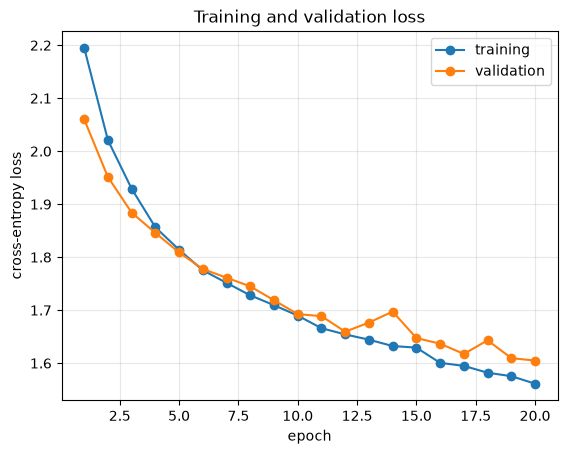

In [3]:
class AuditCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 24, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(24, 48, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d(1),
        )
        self.classifier = nn.Linear(48, 10)

    def forward(self, images):
        return self.classifier(self.features(images).flatten(1))


# Reset model initialization so this cell is reproducible when rerun alone.
torch.manual_seed(SEED)
model = AuditCNN().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=2e-3)
loader = DataLoader(
    TensorDataset(train_images, train_labels), batch_size=128, shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)
training_losses = []
validation_losses = []
for epoch in range(20):
    model.train()
    epoch_loss = 0.0
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        loss = F.cross_entropy(model(images), labels)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * len(images)
    training_losses.append(epoch_loss / len(train_images))

    # Evaluate the same fixed validation set after each training epoch.
    model.eval()
    with torch.no_grad():
        validation_logits = model(validation_images.to(DEVICE))
        validation_loss = F.cross_entropy(
            validation_logits, validation_labels.to(DEVICE)
        )
    validation_losses.append(validation_loss.item())

print(f"final training loss:   {training_losses[-1]:.3f}")
print(f"final validation loss: {validation_losses[-1]:.3f}")

epochs = range(1, len(training_losses) + 1)
plt.plot(epochs, training_losses, marker="o", label="training")
plt.plot(epochs, validation_losses, marker="o", label="validation")
plt.xlabel("epoch")
plt.ylabel("cross-entropy loss")
plt.title("Training and validation loss")
plt.grid(alpha=0.3)
plt.legend();

### Exercise 1 — Establish the aggregate result

Implement `predict_with_confidence`. Return CPU tensors containing predicted class IDs, maximum softmax probabilities, and the complete probability matrix. Then report validation and test accuracy.

In [4]:
@torch.no_grad()
def predict_with_confidence(model, images):
    model.eval()
    # calculate logits, probabilities, predictions, and confidence.
    logits = model(images.to(DEVICE))
    probabilities = F.softmax(logits, dim=1)
    predictions = torch.argmax(probabilities, dim=1)
    confidence = torch.max(probabilities, dim=1).values
    return predictions.cpu(), confidence.cpu(), probabilities.cpu()


validation_predictions, validation_confidence, validation_probabilities = (
    predict_with_confidence(model, validation_images)
)
test_predictions, test_confidence, test_probabilities = predict_with_confidence(
    model, test_images
)
validation_accuracy = (validation_predictions == validation_labels).float().mean().item()
test_accuracy = (test_predictions == test_labels).float().mean().item()
print(f"validation accuracy: {validation_accuracy:.3f}")
print(f"test accuracy:       {test_accuracy:.3f}")

assert validation_probabilities.shape == (len(validation_images), 10)
assert test_confidence.shape == test_labels.shape

validation accuracy: 0.440
test accuracy:       0.440


**Observation.** Training and validation loss decrease together to `1.561` and `1.605`, without a strong sign of overfitting in this run. Validation and test accuracy are both `0.440`, clearly above the `0.100` random baseline.

## 2. Aggregate accuracy can hide subgroup failures

We divide test images into dark, medium, and bright thirds using mean pixel intensity. These are synthetic diagnostic groups—not demographic groups and not inherently meaningful populations. They let us check whether one aggregate number conceals systematic variation.

overall: 0.440
  dark: 0.413 (334 examples)
medium: 0.456 (333 examples)
bright: 0.450 (333 examples)


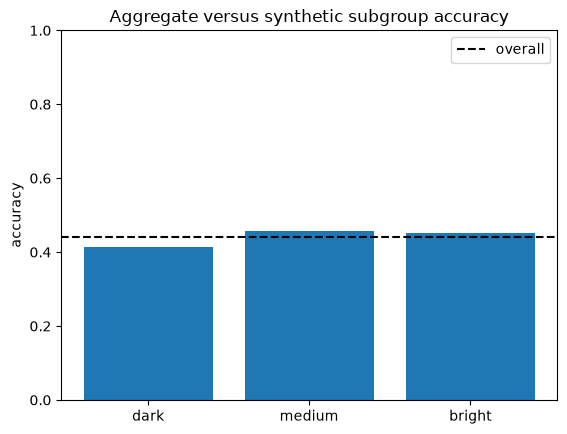

In [5]:
# Exercise 2 — Calculate accuracy separately for each brightness group.
brightness = test_images_raw.mean(axis=(1, 2, 3))
lower, upper = np.quantile(brightness, [1 / 3, 2 / 3])
group_masks = {
    "dark": brightness <= lower,
    "medium": (brightness > lower) & (brightness <= upper),
    "bright": brightness > upper,
}

subgroup_accuracy = {}
for group_name, mask in group_masks.items():
    # compare predictions and labels selected by mask.
    subgroup_accuracy[group_name] = (test_predictions[mask] == test_labels[mask]).float().mean().item()

print(f"overall: {test_accuracy:.3f}")
for group_name, accuracy in subgroup_accuracy.items():
    print(f"{group_name:>6}: {accuracy:.3f} ({group_masks[group_name].sum()} examples)")

plt.bar(subgroup_accuracy.keys(), subgroup_accuracy.values())
plt.axhline(test_accuracy, color="black", linestyle="--", label="overall")
plt.ylim(0, 1)
plt.ylabel("accuracy")
plt.title("Aggregate versus synthetic subgroup accuracy")
plt.legend();

**Observation.** Dark-image accuracy (`0.413`) is modestly below medium (`0.456`) and bright (`0.450`) accuracy. This is an association in this synthetic grouping, not proof that brightness alone causes the gap; class mixture and other image properties may also differ.

## 3. Error frequency is not error cost

Accuracy assigns the same cost to every mistake. Real applications rarely do. Here we create a hypothetical cost matrix: correct predictions cost zero, ordinary errors cost one, and missing a `truck` costs five. This is only an illustration—not a claim that CIFAR-10 is safety-critical.

For each example, select `cost_matrix[true_class, predicted_class]` and average those costs.

In [6]:
# Exercise 3 — Compare error rate with hypothetical average error cost.
cost_matrix = np.ones((10, 10), dtype=float)
np.fill_diagonal(cost_matrix, 0.0)
truck_id = class_names.index("truck")
cost_matrix[truck_id, :] = 5.0
cost_matrix[truck_id, truck_id] = 0.0

# index cost_matrix using every true and predicted class pair.
example_costs = cost_matrix[test_labels.numpy(), test_predictions.numpy()]
average_cost = example_costs.mean()
error_rate = (test_predictions != test_labels).float().mean().item()
print(f"error rate:   {error_rate:.3f}")
print(f"average cost: {average_cost:.3f}")

assert example_costs.shape == (len(test_labels),)

error rate:   0.560
average cost: 0.772


**Observation.** The average hypothetical cost (`0.772`) exceeds the ordinary error rate (`0.560`) because missed trucks receive five times the cost of other mistakes. Accuracy alone does not express that priority.

## 4. Controlled distribution shift

The clean test set resembles the training distribution. Deployment images may contain sensor noise, compression, blur, unusual lighting, or different viewpoints. We add increasing Gaussian noise to the raw `[0,1]` images, then normalize them exactly as during training.

A corruption curve is more informative than testing only one arbitrary severity.

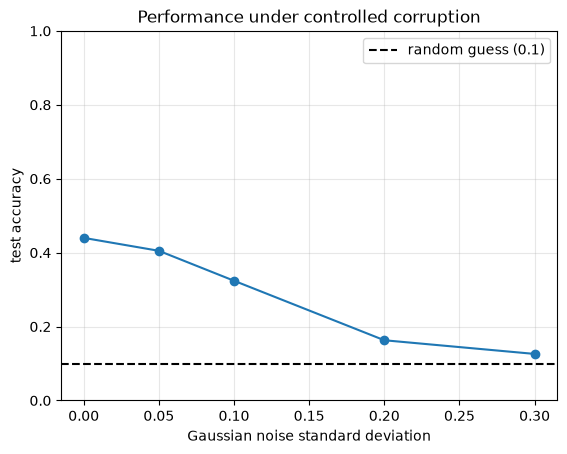

In [7]:
# Exercise 4 — Measure accuracy across all noise severities.
noise_levels = [0.0, 0.05, 0.10, 0.20, 0.30]
generator = np.random.default_rng(SEED)
shift_accuracy = []
for noise_level in noise_levels:
    noisy_raw = np.clip(
        test_images_raw + generator.normal(0, noise_level, test_images_raw.shape),
        0, 1,
    )
    # prepare noisy_raw, predict it, and append its accuracy.
    noisy_images = prepare_images(noisy_raw)
    noisy_predictions, _, _ = predict_with_confidence(model, noisy_images)
    accuracy = (noisy_predictions == test_labels).float().mean().item()
    shift_accuracy.append(accuracy)

random_guess_accuracy = 1.0 / len(class_names)
plt.plot(noise_levels, shift_accuracy, marker="o")
plt.axhline(
    random_guess_accuracy, color="black", linestyle="--",
    label=f"random guess ({random_guess_accuracy:.1f})",
)
plt.xlabel("Gaussian noise standard deviation")
plt.ylabel("test accuracy")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.title("Performance under controlled corruption")
plt.legend();

assert len(shift_accuracy) == len(noise_levels)

**Observation.** Accuracy decreases steadily from `0.44` on clean images to about `0.13` at noise standard deviation `0.30`, only slightly above random guessing. Ordinary clean-test accuracy therefore overstates robustness to this corruption.

## 5. Selective prediction: accuracy versus coverage

A model can abstain when its maximum softmax probability is below a threshold. **Coverage** is the fraction of examples accepted. **Selective accuracy** is accuracy only among accepted examples.

Abstention can reduce errors passed downstream, but it also leaves some cases unresolved. Softmax confidence may be miscalibrated, so this experiment does not prove that accepted predictions are safe. Point labels in the plots show the absolute number of accepted test examples; this is especially important when a high accuracy is based on very low coverage.

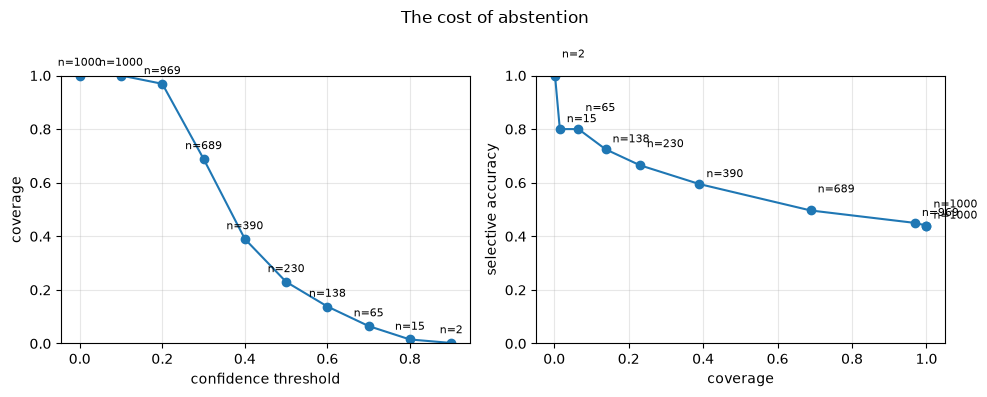

In [13]:
# Exercise 5 — Calculate coverage and accepted-set accuracy.
thresholds = np.linspace(0.0, 0.9, 10)
coverage = []
accepted_counts = []
selective_accuracy = []
for threshold in thresholds:
    accepted = test_confidence >= threshold
    # append accepted fraction and accuracy among accepted examples.
    # Use np.nan when no examples are accepted.
    accepted_count = int(accepted.sum().item())
    accepted_counts.append(accepted_count)
    coverage.append(accepted.float().mean().item())
    if accepted_count > 0:
        selective_accuracy.append((test_predictions[accepted] == test_labels[accepted]).float().mean().item())
    else:   
        selective_accuracy.append(np.nan)  # Use np.nan when no examples are accepted.

figure, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(thresholds, coverage, marker="o")
axes[0].set(xlabel="confidence threshold", ylabel="coverage", ylim=(0, 1))
axes[1].plot(coverage, selective_accuracy, marker="o")
axes[1].set(xlabel="coverage", ylabel="selective accuracy", ylim=(0, 1))
for index, (threshold, accepted_count) in enumerate(
    zip(thresholds, accepted_counts)
):
    axes[0].annotate(
        f"n={accepted_count}", (threshold, coverage[index]),
        xytext=(0, 7), textcoords="offset points",
        ha="center", fontsize=8,
    )
    if not np.isnan(selective_accuracy[index]):
        axes[1].annotate(
            f"n={accepted_count}",
            (coverage[index], selective_accuracy[index]),
            xytext=(5, 5 + 8 * (index % 2)),
            textcoords="offset points", fontsize=8,
        )
for axis in axes: axis.grid(alpha=0.3)
figure.suptitle("The cost of abstention")
figure.tight_layout()

**Observation.** Raising the confidence threshold generally reduces coverage while increasing accuracy among accepted examples, but the high-accuracy endpoint contains very few examples and is therefore unstable. Only nine points are visibly distinct in the coverage–accuracy plot because two thresholds accept exactly the same examples and consequently have identical coverage and selective accuracy.

## 6. A privacy–utility proxy

We reduce spatial resolution and enlarge the result back to $32\times32$. Lower resolution removes visual detail and may reduce classification utility. It is only a **privacy proxy**: identities or sensitive attributes may remain inferable, and the original camera may already have captured high-resolution data.

A real privacy analysis must define the sensitive information, attacker, data lifecycle, and acceptable risk.

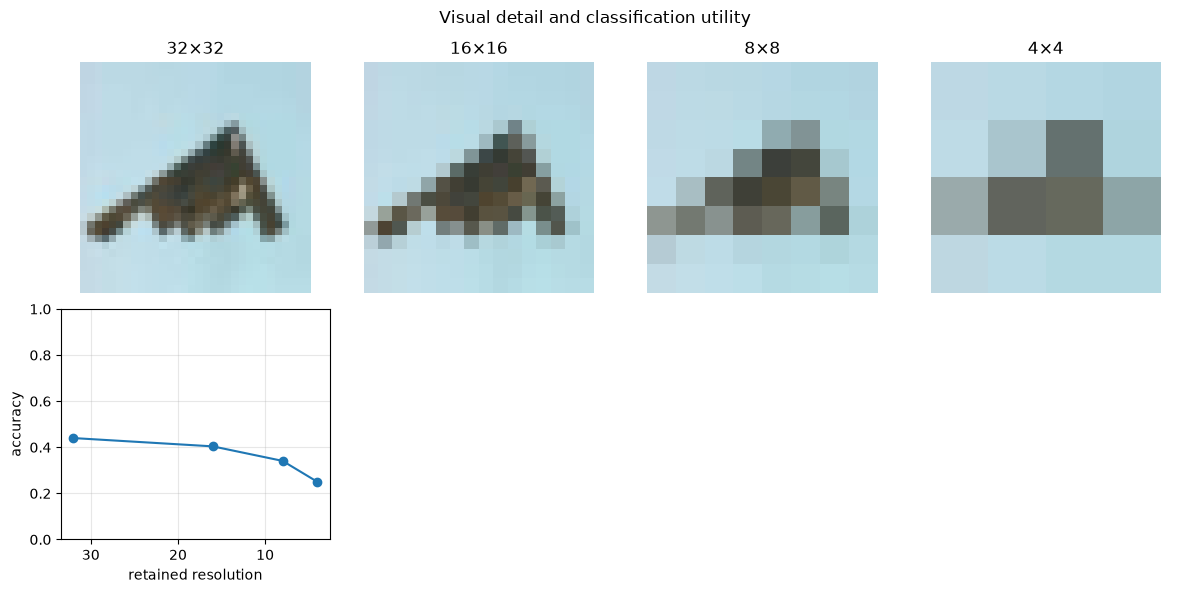

In [14]:
def reduce_and_restore_resolution(raw_images, size):
    tensor = torch.tensor(raw_images.transpose(0, 3, 1, 2), dtype=torch.float32)
    reduced = F.interpolate(tensor, size=(size, size), mode="area")
    restored = F.interpolate(reduced, size=(32, 32), mode="nearest")
    return restored.permute(0, 2, 3, 1).numpy()


# Exercise 6 — Evaluate utility at every retained resolution.
resolutions = [32, 16, 8, 4]
resolution_accuracy = []
restored_examples = []
for size in resolutions:
    restored_raw = reduce_and_restore_resolution(test_images_raw, size)
    restored_examples.append(restored_raw[0])
    # prepare restored_raw, predict it, and append accuracy.
    restored_images = prepare_images(restored_raw)
    restored_predictions, _, _ = predict_with_confidence(model, restored_images)
    accuracy = (restored_predictions == test_labels).float().mean().item()
    resolution_accuracy.append(accuracy)

figure, axes = plt.subplots(2, len(resolutions), figsize=(12, 6))
for column, (size, image, accuracy) in enumerate(
    zip(resolutions, restored_examples, resolution_accuracy)
):
    axes[0, column].imshow(image)
    axes[0, column].set_title(f"{size}×{size}")
    axes[0, column].axis("off")
axes[1, 0].plot(resolutions, resolution_accuracy, marker="o")
axes[1, 0].invert_xaxis()
axes[1, 0].set(xlabel="retained resolution", ylabel="accuracy", ylim=(0, 1))
axes[1, 0].grid(alpha=0.3)
for axis in axes[1, 1:]: axis.axis("off")
figure.suptitle("Visual detail and classification utility")
figure.tight_layout()

## 7. A compact model card

A model card does not make a system responsible by itself. It records intended use, evidence, limitations, and ownership so that decisions are easier to inspect.

### Exercise 7

Complete this short card after running the audit:

- **Model and task:** A small CNN classifying CIFAR-10 images into ten classes.
- **Intended educational use:** Practicing model evaluation, robustness checks, abstention, and limitation reporting.
- **Out-of-scope uses:** Safety-critical decisions or claims about demographic fairness and real privacy.
- **Training and evaluation data:** Disjoint, class-balanced CIFAR-10 subsets with 4,000 training, 1,000 validation, and 1,000 test images.
- **Aggregate result:** Validation and test accuracy are both `0.440`.
- **Subgroup or corruption findings:** Dark-image accuracy is slightly lower, and strong Gaussian noise reduces accuracy close to random guessing.
- **Abstention behavior:** Higher thresholds can improve accepted-set accuracy but sharply reduce coverage; very high accuracy may represent only a few examples.
- **Known limitations and failure modes:** Low overall accuracy, synthetic subgroups and corruptions, uncalibrated confidence, and a small educational model.
- **Human oversight or fallback:** Reject or review uncertain and shifted inputs rather than trusting predictions automatically.

## 8. Reflection

1. Why can overall accuracy hide an important model weakness?

   Overall accuracy averages across all examples, so weaker performance for a particular subgroup or condition can be hidden by stronger results elsewhere.

2. Why is a cost matrix a human or organizational choice rather than a property learned automatically from accuracy?

   Accuracy treats all mistakes equally, whereas a cost matrix encodes which errors matter more in a particular application. Those priorities must come from people and the deployment context.

3. What is the difference between distribution-shift robustness and ordinary test accuracy?

   Ordinary test accuracy measures performance on data similar to the benchmark. Robustness measures whether performance remains useful when deployment conditions differ, such as under sensor noise.

4. Why does higher selective accuracy not prove that confidence is calibrated or that deployment is safe?

   Selective accuracy may be based on very few accepted examples, and softmax confidence can be overconfident or miscalibrated. It also does not test every deployment hazard.

5. Why does reducing image resolution not guarantee privacy?

   Low-resolution images may still reveal identities or sensitive attributes, and the original sensor may already have captured detailed data. Privacy depends on the complete collection and storage process.

6. Which audit result would most change how you deploy or document this model, and why?

   The corruption result would most affect deployment because accuracy falls from `0.44` to near random guessing under strong noise. I would document supported input conditions and add shift detection or human review.